In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
# import matplotlib.cm
import scipy
import squarify

In [28]:
fmri = sns.load_dataset("fmri")
fmri.head()

,subject,timepoint,event,region,signal
0,s13,18,stim,parietal,-0.017552
1,s5,14,stim,parietal,-0.080883
2,s12,18,stim,parietal,-0.081033
3,s11,18,stim,parietal,-0.046134
4,s10,18,stim,parietal,-0.037970


<Axes: xlabel='timepoint', ylabel='signal'>

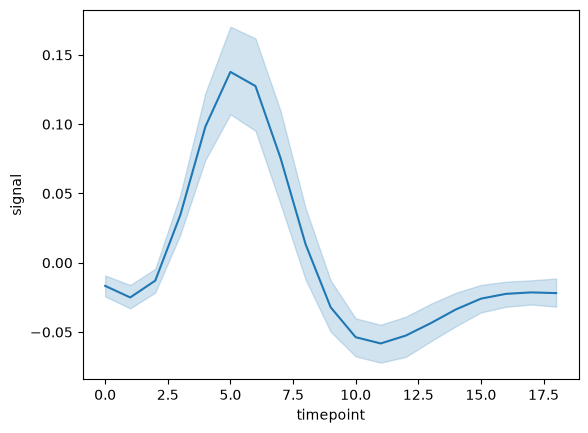

In [29]:
sns.lineplot(data=fmri, x="timepoint",y="signal")

In [30]:
type(fmri)

pandas.DataFrame

Text(0, 0.5, 'Percent signal change')

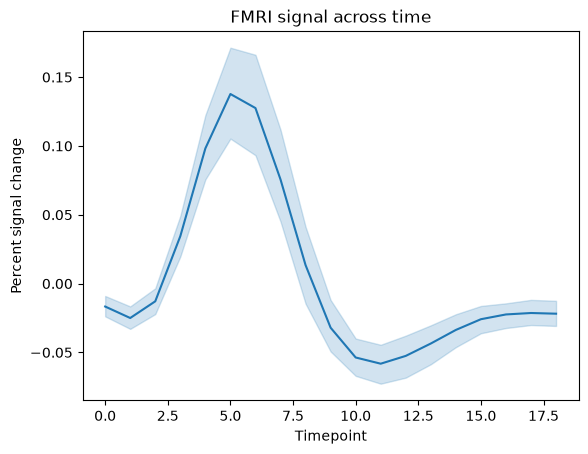

In [31]:
sns.lineplot(x="timepoint", y="signal", data=fmri)

plt.title('FMRI signal across time')
plt.xlabel('Timepoint')
plt.ylabel('Percent signal change')

<Axes: xlabel='timepoint', ylabel='signal'>

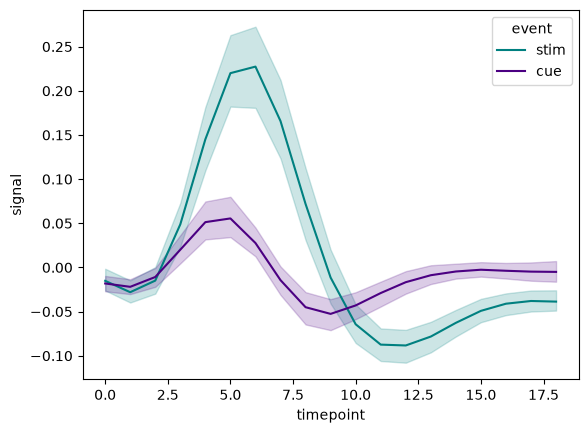

In [32]:
sns.lineplot(x='timepoint', y='signal', hue='event', palette=['teal', 'indigo'], data=fmri)

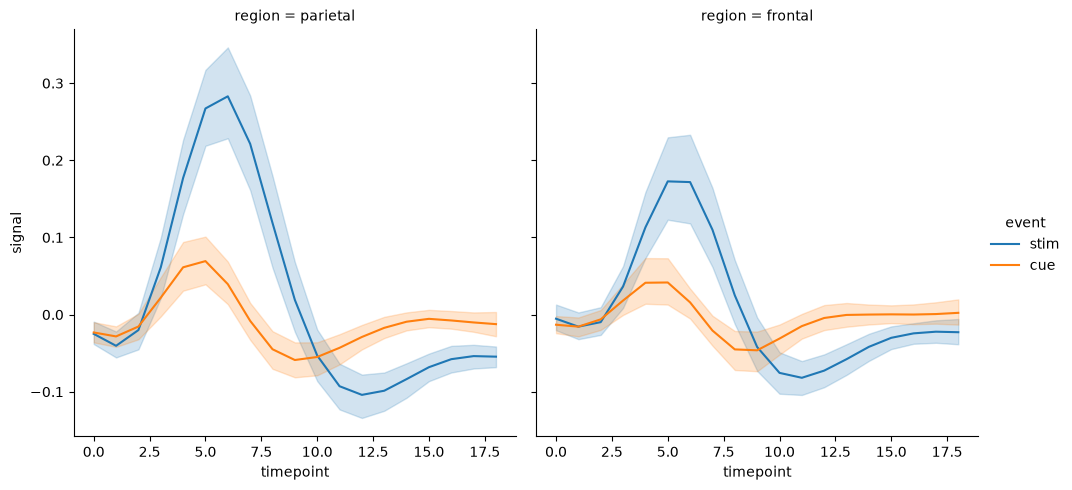

In [33]:
sns.relplot(x='timepoint', y='signal', col='region', hue='event', kind='line', data=fmri)

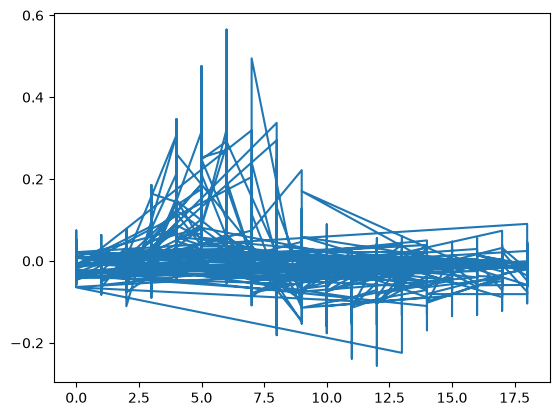

In [34]:
plt.plot(fmri.timepoint, fmri.signal)

In [35]:
fmri

,subject,timepoint,event,region,signal
0,s13,18,stim,parietal,-0.017552
1,s5,14,stim,parietal,-0.080883
2,s12,18,stim,parietal,-0.081033
3,s11,18,stim,parietal,-0.046134
4,s10,18,stim,parietal,-0.037970
...,...,...,...,...,...
1059,s0,8,cue,frontal,0.018165
1060,s13,7,cue,frontal,-0.029130
1061,s12,7,cue,frontal,-0.004939
1062,s11,7,cue,frontal,-0.025367


In [36]:
new_df = pd.DataFrame({
    'years':[2014,2015,2016,2017,2018,2019,2020],
    'sales':[4800,4900,5000,5700,6500,5000,6700]
})
new_df.head()

,years,sales
0,2014,4800
1,2015,4900
2,2016,5000
3,2017,5700
4,2018,6500


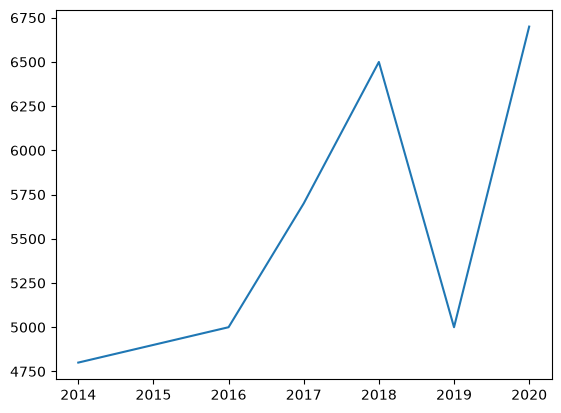

In [37]:
plt.plot(new_df.years, new_df.sales)

Text(0, 0.5, 'Sales')

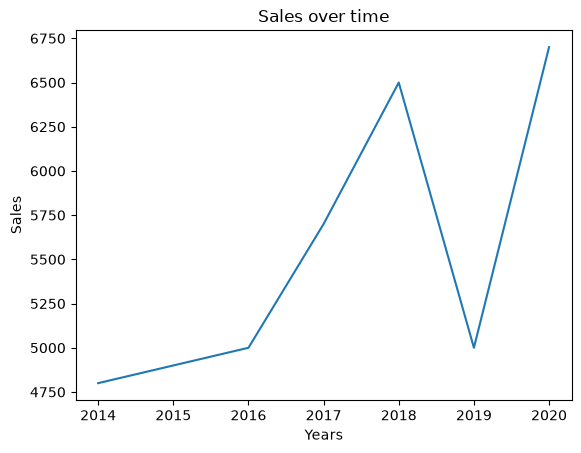

In [38]:
plt.plot(new_df.years, new_df.sales)
plt.title("Sales over time")
plt.xlabel("Years")
plt.ylabel("Sales")

In [39]:
tips = sns.load_dataset("tips")
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='day', ylabel='total_bill'>

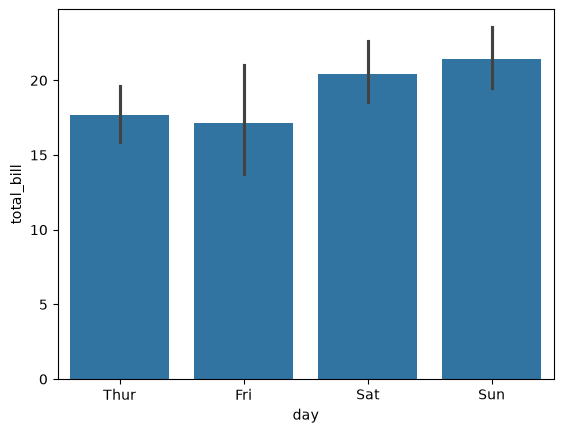

In [40]:
sns.barplot(x='day', y='total_bill', data=tips)

Text(0, 0.5, 'Total Bill')

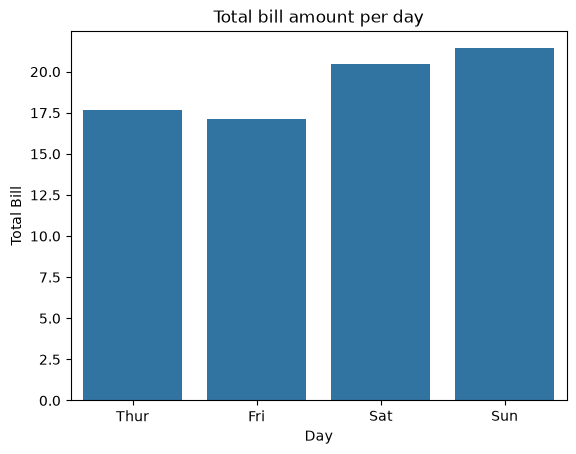

In [41]:
sns.barplot(x='day', y='total_bill', data=tips, errorbar=None)
plt.title('Total bill amount per day')
plt.xlabel('Day')
plt.ylabel('Total Bill')

<Axes: xlabel='total_bill', ylabel='day'>

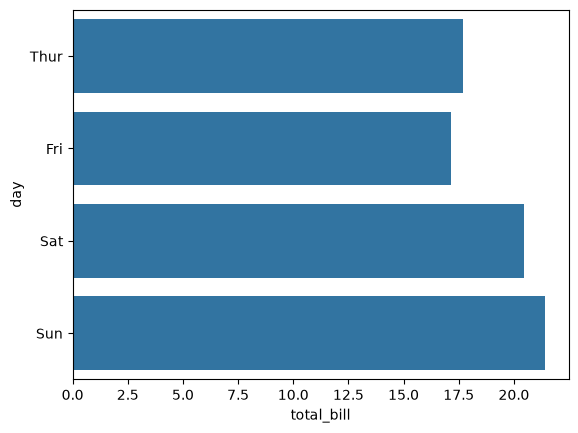

In [42]:
sns.barplot(y='day', x='total_bill', data=tips, errorbar=None)

<Axes: xlabel='day', ylabel='total_bill'>

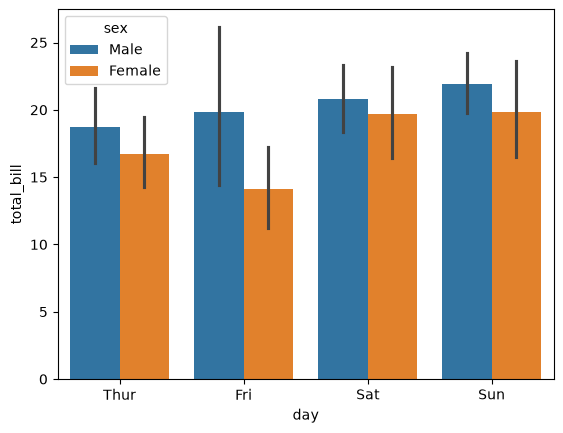

In [43]:
sns.barplot(x='day', y='total_bill', hue='sex', data=tips)

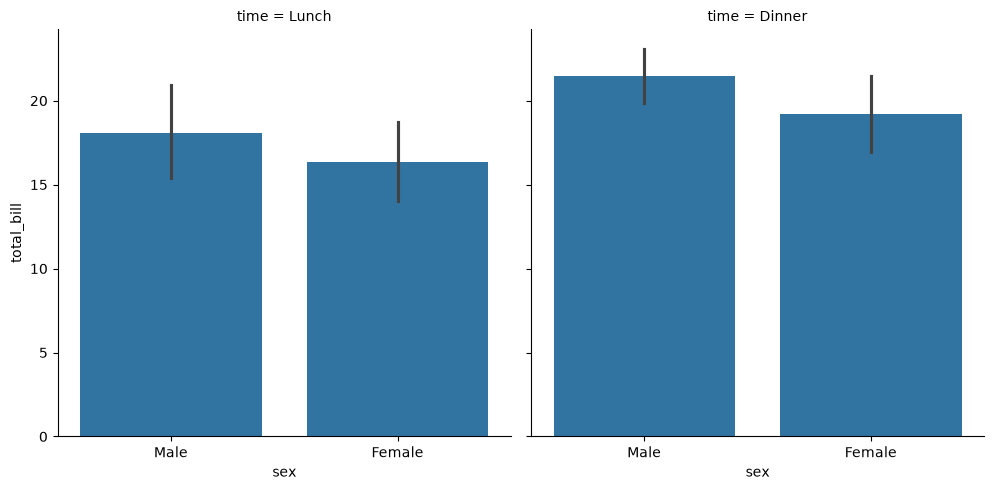

In [44]:
sns.catplot(x='sex', y='total_bill', col='time', data=tips, kind='bar')

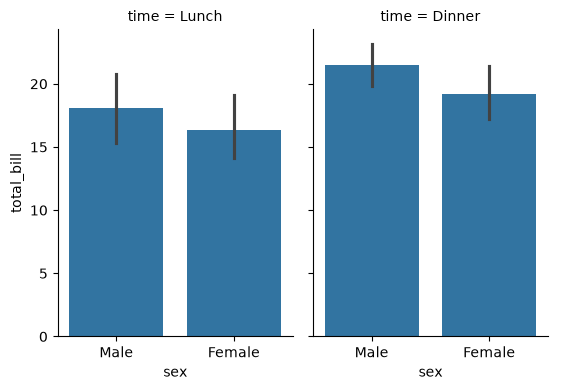

In [45]:
sns.catplot(x='sex', y='total_bill', col='time', data=tips, kind='bar', height=4, aspect=.7)

<BarContainer object of 244 artists>

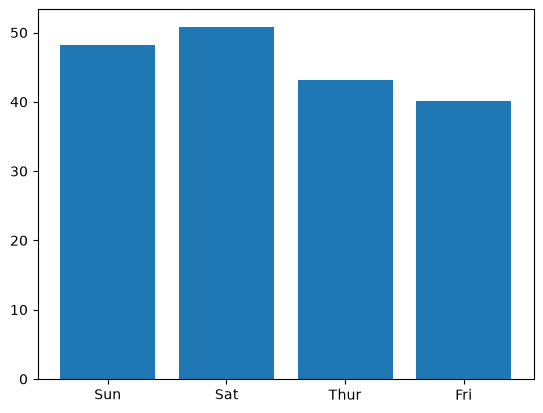

In [46]:
plt.bar(x=tips.day, height=tips.total_bill)
# can also do it like plt.bar(tips.day, tips.total_bill, data=tips)
# matplotlib can even assume the data so might not even need to state it

Text(0, 0.5, 'Total bill amount')

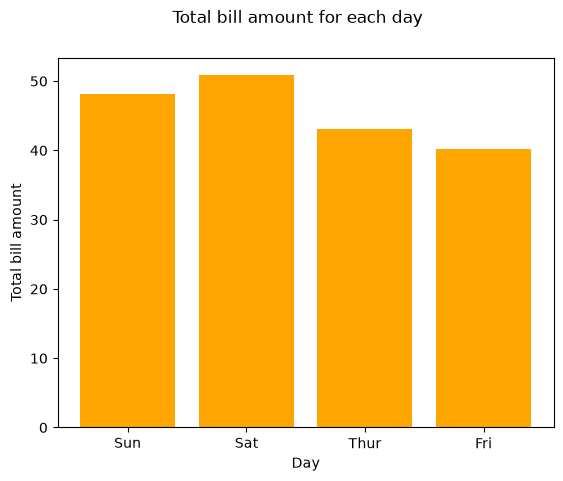

In [47]:
plt.bar(x=tips.day, height=tips.total_bill, color='orange')
plt.suptitle('Total bill amount for each day')
plt.xlabel('Day')
plt.ylabel('Total bill amount')

In [48]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [49]:
male = tips[tips['sex'] == 'Male']
female = tips[tips['sex'] == 'Female']

mday = male.groupby('day').mean(numeric_only=True)
fday = female.groupby('day').mean(numeric_only=True)

totals = mday.merge(fday, right_index=True, left_index=True) # it means that the first row lines up with the other

totals['total_tips'] = totals['tip_x'] + totals['tip_y'] # taking the fem and m totals and tips and dividing

totals['prop_mal'] = np.true_divide(totals['tip_x'], totals['total_tips']) * 100
totals['prop_fem'] = np.true_divide(totals['tip_y'], totals['total_tips']) * 100

totals.head()

,total_bill_x,tip_x,size_x,total_bill_y,tip_y,size_y,total_tips,prop_mal,prop_fem
day,,,,,,,,,
Thur,18.714667,2.980333,2.433333,16.715312,2.575625,2.468750,5.555958,53.642111,46.357889
Fri,19.857000,2.693000,2.100000,14.145556,2.781111,2.111111,5.474111,49.195202,50.804798
Sat,20.802542,3.083898,2.644068,19.680357,2.801786,2.250000,5.885684,52.396600,47.603400
Sun,21.887241,3.220345,2.810345,19.872222,3.367222,2.944444,6.587567,48.885192,51.114808


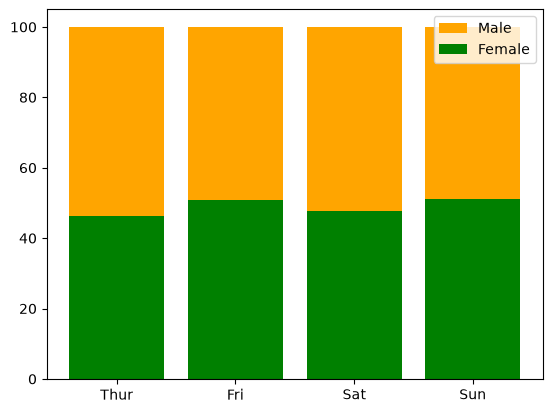

In [50]:
plt.bar(totals.index, totals.prop_mal, label='Male', color='orange', bottom=totals.prop_fem)
plt.bar(totals.index, totals.prop_fem, label='Female', color='green')
plt.legend()

In [51]:
data = np.random.randn(100)
data

array([-0.07109252, -1.10594239, -0.37039265, -0.16262199,  0.05869031,
        1.19597291,  0.61175979,  0.93127075,  0.72818566, -1.92965881,
       -1.57706967, -2.01591526, -0.22674784, -0.46519518, -0.21248068,
        0.22805909, -0.36933514,  1.39274825, -0.53200882, -1.89676349,
        1.14347037,  3.33198532, -0.16611205,  0.49060611,  0.22863477,
       -0.59913887,  1.32776374, -1.06892112, -0.09283562,  0.10325461,
        1.43223249, -0.80345664, -1.29339364, -0.1728713 ,  2.14251785,
       -0.50656408,  0.35411886, -1.42582719, -0.35225054,  0.14557426,
        0.33835703,  0.80131291, -1.72116314, -0.01066666,  1.78267173,
       -1.31801136,  0.6891762 , -0.71816111,  1.97706428, -0.33473905,
       -1.56585427, -0.07583641, -0.97147598,  0.06841124,  0.21600905,
       -0.28584984, -0.02256139,  0.57961377,  1.42454212,  1.58475757,
       -0.336252  ,  0.80688755, -1.14951455, -0.67085727,  0.81235292,
        0.29654505, -2.38596212,  1.82588318,  0.62542431,  0.48

(array([ 5.,  9., 13., 19., 21., 16., 11.,  5.,  0.,  1.]),
 array([-2.38596212, -1.81416738, -1.24237263, -0.67057789, -0.09878314,
         0.4730116 ,  1.04480635,  1.61660109,  2.18839583,  2.76019058,
         3.33198532]),
 <BarContainer object of 10 artists>)

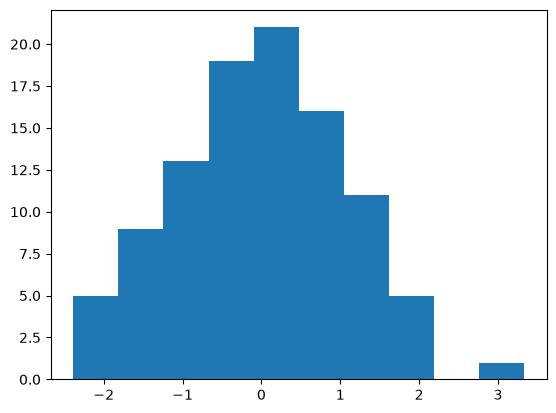

In [52]:
plt.hist(data)

(array([ 2.,  3.,  5.,  4.,  7.,  6.,  6., 13., 12.,  9., 10.,  6.,  7.,
         4.,  3.,  2.,  0.,  0.,  0.,  1.]),
 array([-2.38596212, -2.10006475, -1.81416738, -1.52827001, -1.24237263,
        -0.95647526, -0.67057789, -0.38468052, -0.09878314,  0.18711423,
         0.4730116 ,  0.75890897,  1.04480635,  1.33070372,  1.61660109,
         1.90249846,  2.18839583,  2.47429321,  2.76019058,  3.04608795,
         3.33198532]),
 <BarContainer object of 20 artists>)

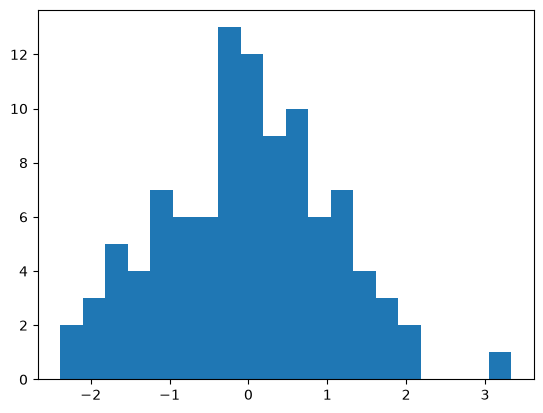

In [53]:
plt.hist(data, bins=20)

Text(0.5, 0, 'Frequency of random values')

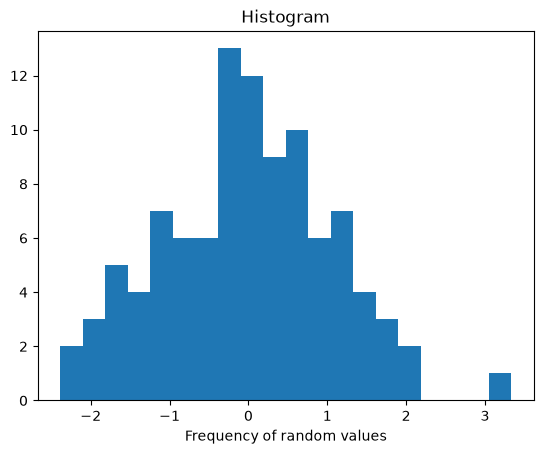

In [54]:
plt.hist(data, bins=20)
plt.title("Histogram")
plt.xlabel("Frequency of random values")

(array([ 1.,  0.,  0.,  1.,  5.,  2.,  2.,  8.,  5.,  9., 12., 11., 14.,
        10.,  6.,  5.,  2.,  4.,  1.,  2.]),
 array([-2.97457519, -2.70914622, -2.44371726, -2.17828829, -1.91285933,
        -1.64743036, -1.3820014 , -1.11657244, -0.85114347, -0.58571451,
        -0.32028554, -0.05485658,  0.21057239,  0.47600135,  0.74143032,
         1.00685928,  1.27228825,  1.53771721,  1.80314618,  2.06857514,
         2.33400411]),
 <BarContainer object of 20 artists>)

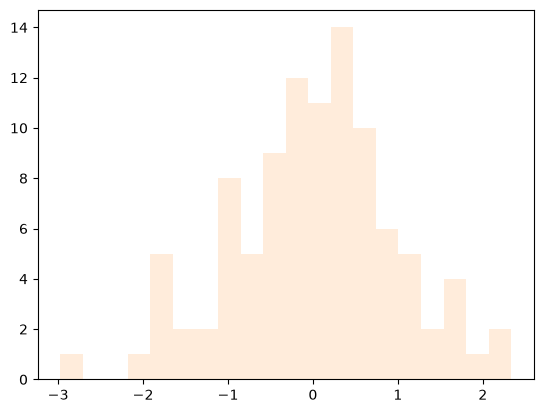

In [55]:
data2 = np.random.randn(100)
plt.hist(data2, bins=20, color='peachpuff', alpha=0.5)

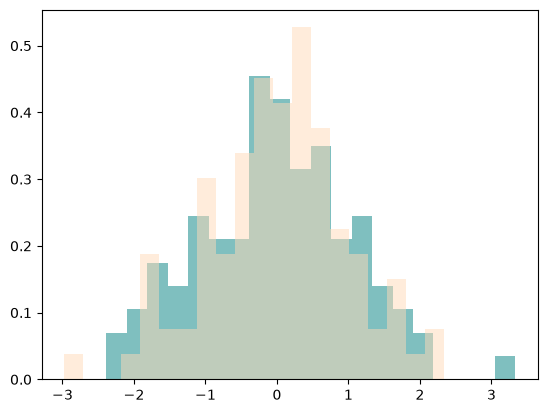

In [56]:
plt.hist(data, bins=20, color='teal', alpha=0.5, density=True)
plt.hist(data2, bins=20, color='peachpuff', alpha=0.5, density=True)
plt.show()

C:\Users\hites\AppData\Local\Temp\ipykernel_27984\1851847670.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data)


<Axes: ylabel='Density'>

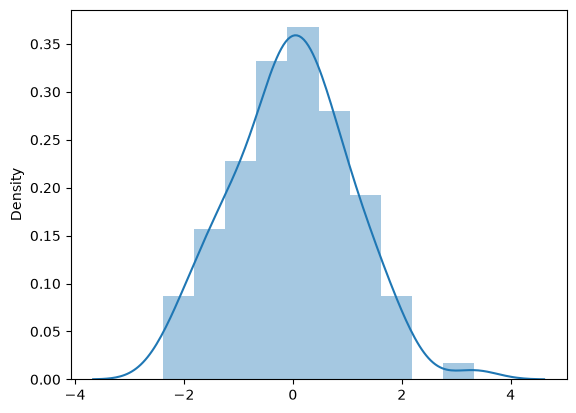

In [57]:
sns.distplot(data)

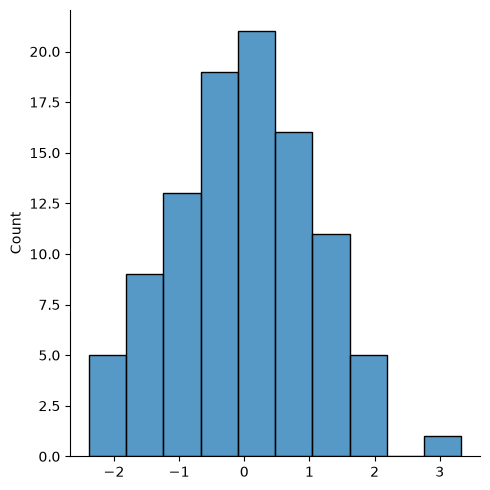

In [58]:
sns.displot(data)

<Axes: ylabel='Count'>

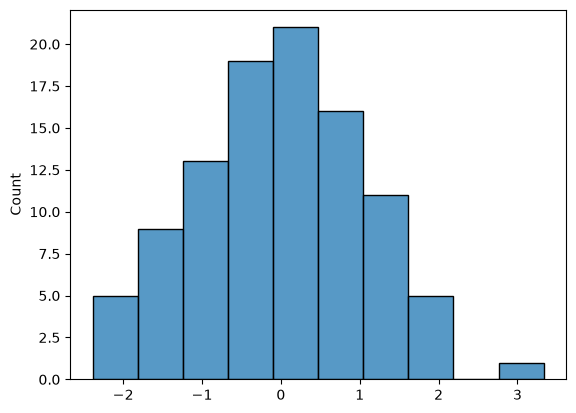

In [59]:
sns.histplot(data)

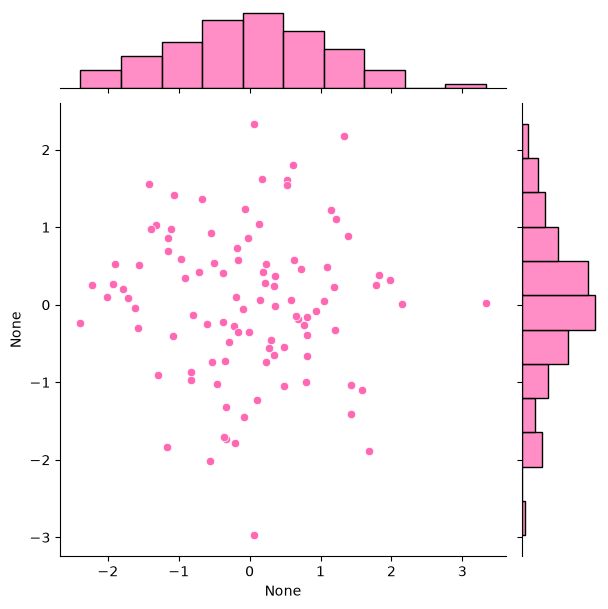

In [60]:
sns.jointplot(x=data, y=data2, color='hotpink')

In [61]:
iris = sns.load_dataset("iris")
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


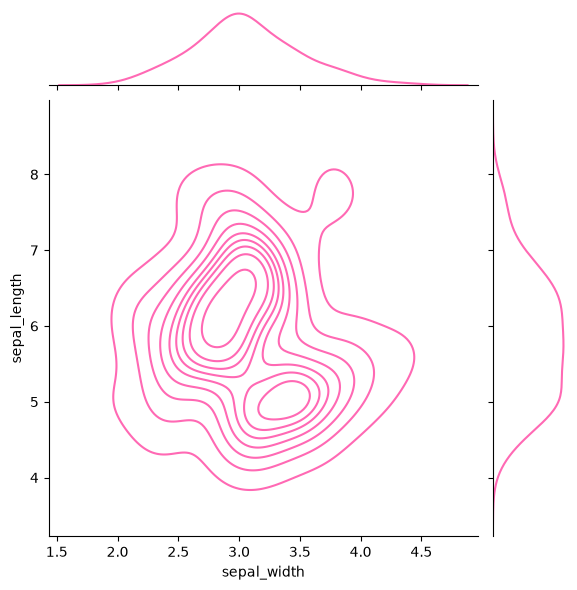

In [62]:
sns.jointplot(x=iris['sepal_width'], y=iris['sepal_length'], color='hotpink', kind='kde')

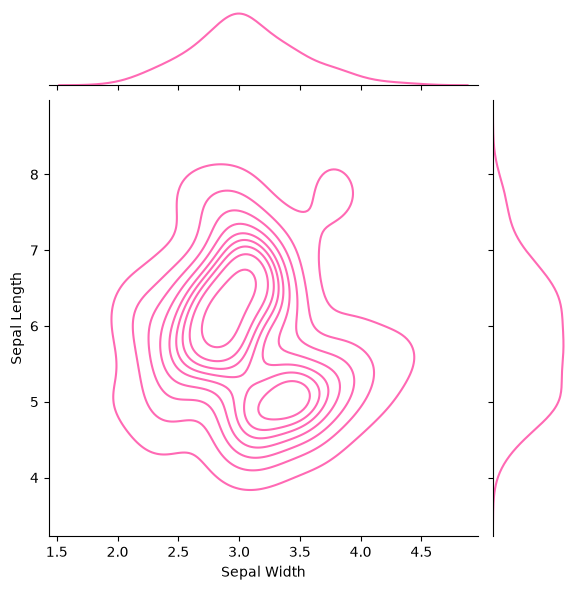

In [63]:
sns.jointplot(x=iris['sepal_width'], y=iris['sepal_length'],
              color='hotpink', kind='kde').set_axis_labels("Sepal Width", "Sepal Length")

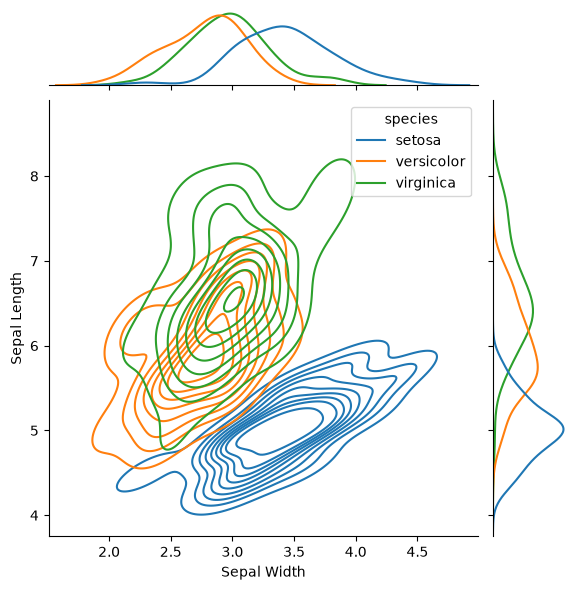

In [64]:
sns.jointplot(x=iris['sepal_width'], y=iris['sepal_length'], kind='kde', hue=iris.species).set_axis_labels("Sepal Width", "Sepal Length")

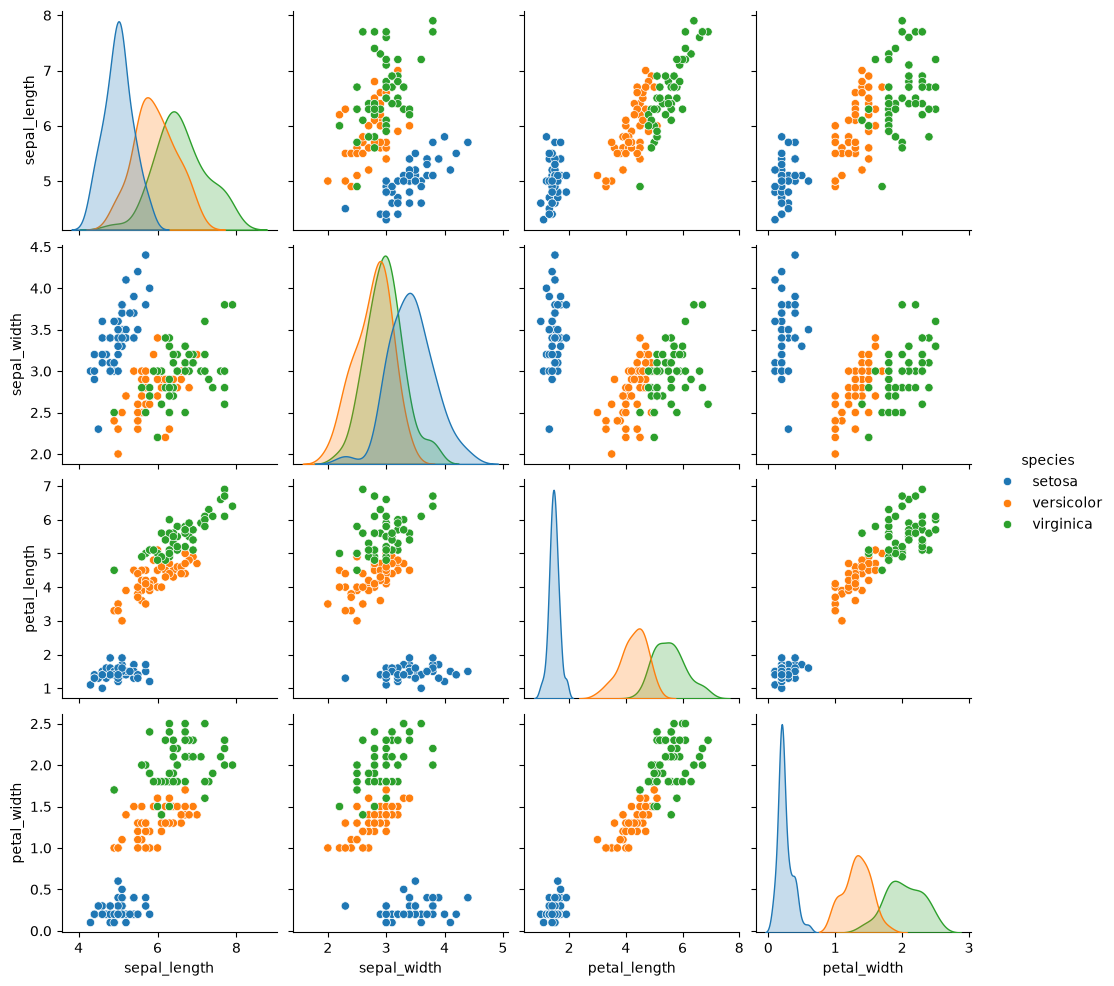

In [65]:
sns.pairplot(iris, hue='species')

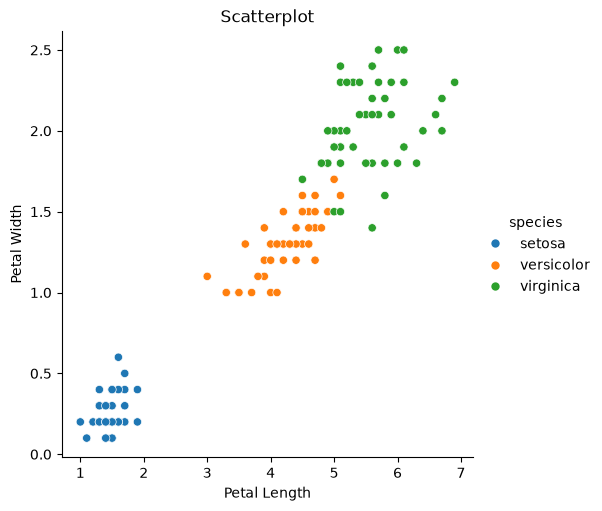

In [66]:
sns.relplot(data=iris, x='petal_length', y='petal_width', hue='species').set(
    title="Scatterplot", xlabel="Petal Length", ylabel="Petal Width")

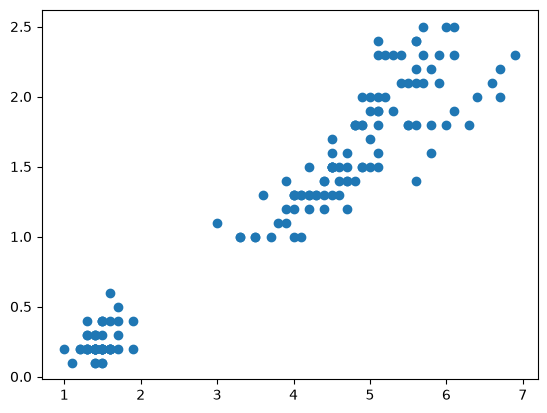

In [67]:
plt.scatter(iris['petal_length'], iris['petal_width'])

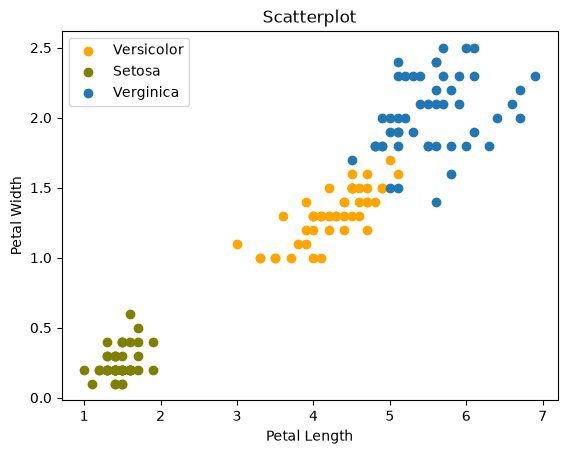

In [68]:
vers = iris[iris['species'] == 'versicolor']
setosa = iris[iris['species'] == 'setosa']
verg = iris[iris['species'] == 'virginica']

plt.scatter(vers.petal_length, vers.petal_width, c='orange')
plt.scatter(setosa.petal_length, setosa.petal_width, c='olive')
plt.scatter(verg.petal_length, verg.petal_width)

plt.title("Scatterplot")
plt.xlabel("Petal Length")
plt.ylabel("Petal Width")

plt.legend(labels=['Versicolor', 'Setosa', 'Verginica'])

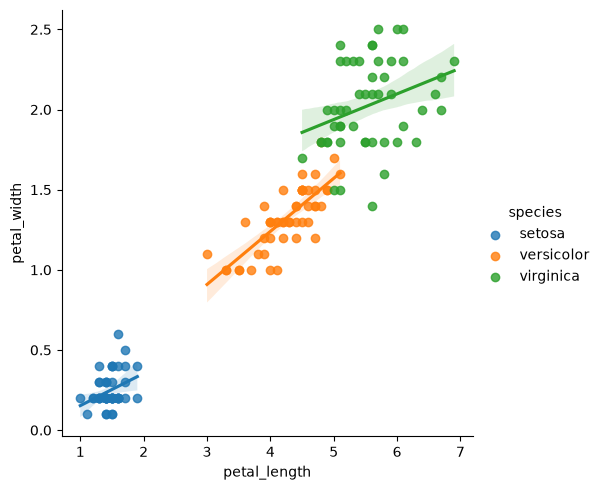

In [69]:
sns.lmplot(data=iris, x='petal_length', y='petal_width', hue='species')

<Axes: xlabel='petal_length', ylabel='petal_width'>

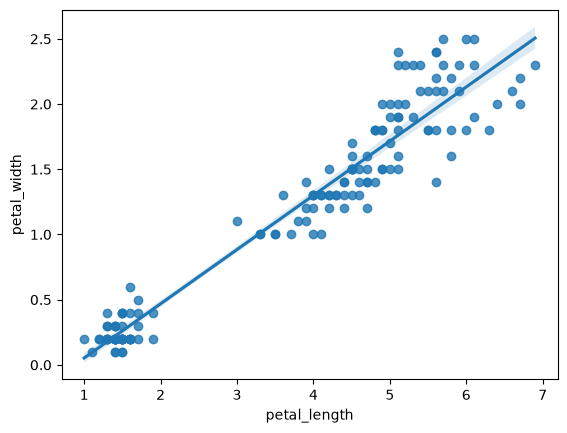

In [70]:
sns.regplot(data=iris, x='petal_length', y='petal_width')

In [71]:
flights = sns.load_dataset('flights')
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [72]:
fp = flights.pivot(index='year', columns='month', values='passengers')
fp

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
1949,112,118,132,129,121,135,148,148,136,119,104,118
1950,115,126,141,135,125,149,170,170,158,133,114,140
1951,145,150,178,163,172,178,199,199,184,162,146,166
1952,171,180,193,181,183,218,230,242,209,191,172,194
1953,196,196,236,235,229,243,264,272,237,211,180,201
1954,204,188,235,227,234,264,302,293,259,229,203,229
1955,242,233,267,269,270,315,364,347,312,274,237,278
1956,284,277,317,313,318,374,413,405,355,306,271,306
1957,315,301,356,348,355,422,465,467,404,347,305,336


<Axes: xlabel='month', ylabel='year'>

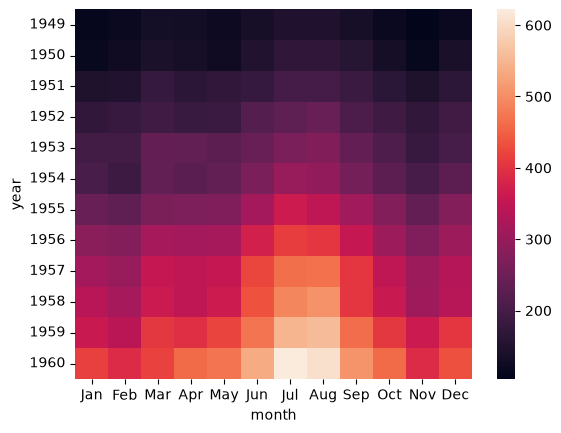

In [73]:
sns.heatmap(fp)

<Axes: xlabel='month', ylabel='year'>

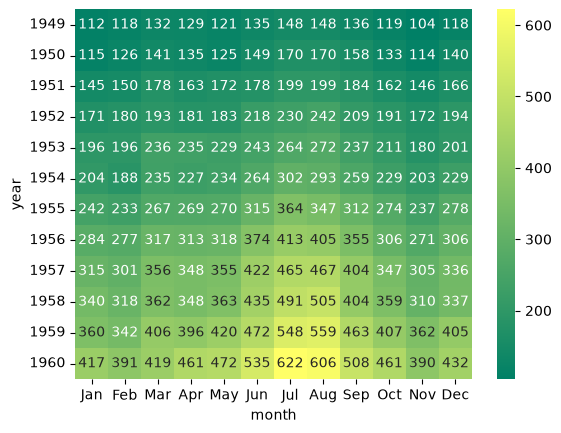

In [74]:
sns.heatmap(fp, annot=True, fmt='d', cmap='summer')

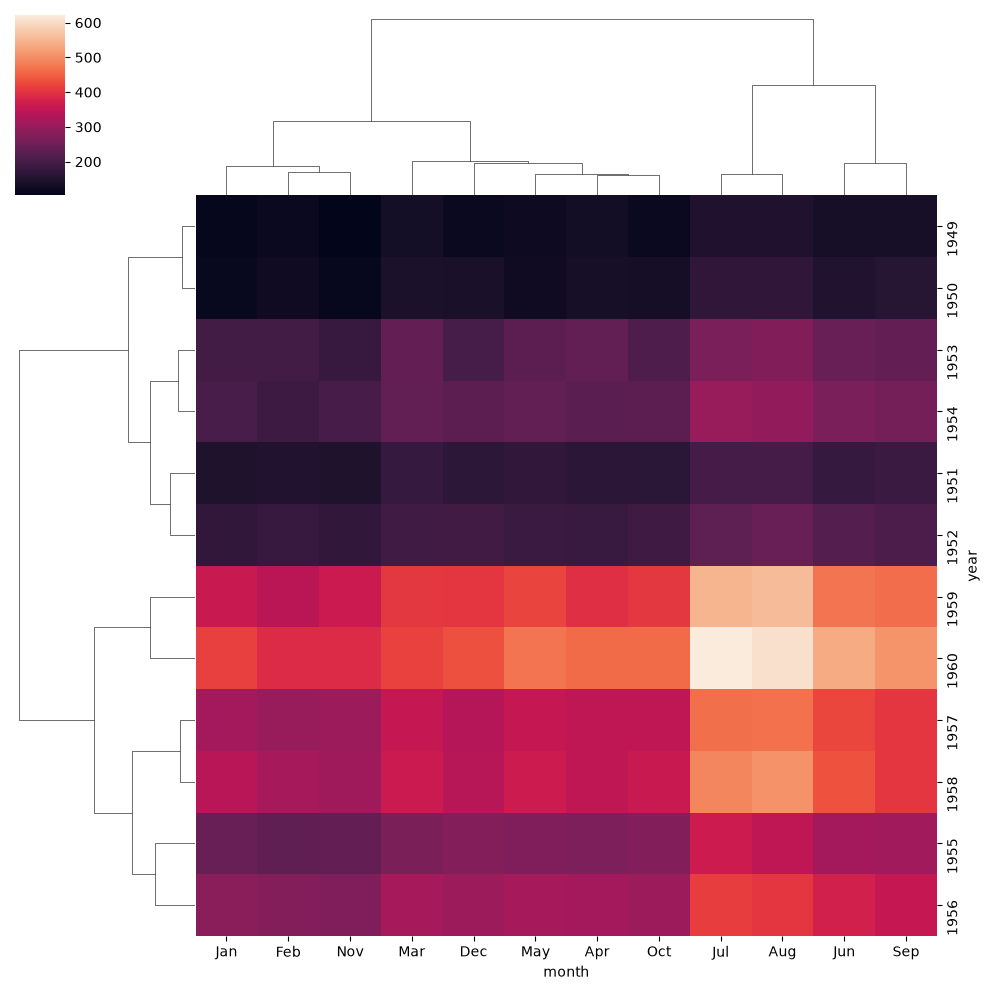

In [75]:
sns.clustermap(fp)

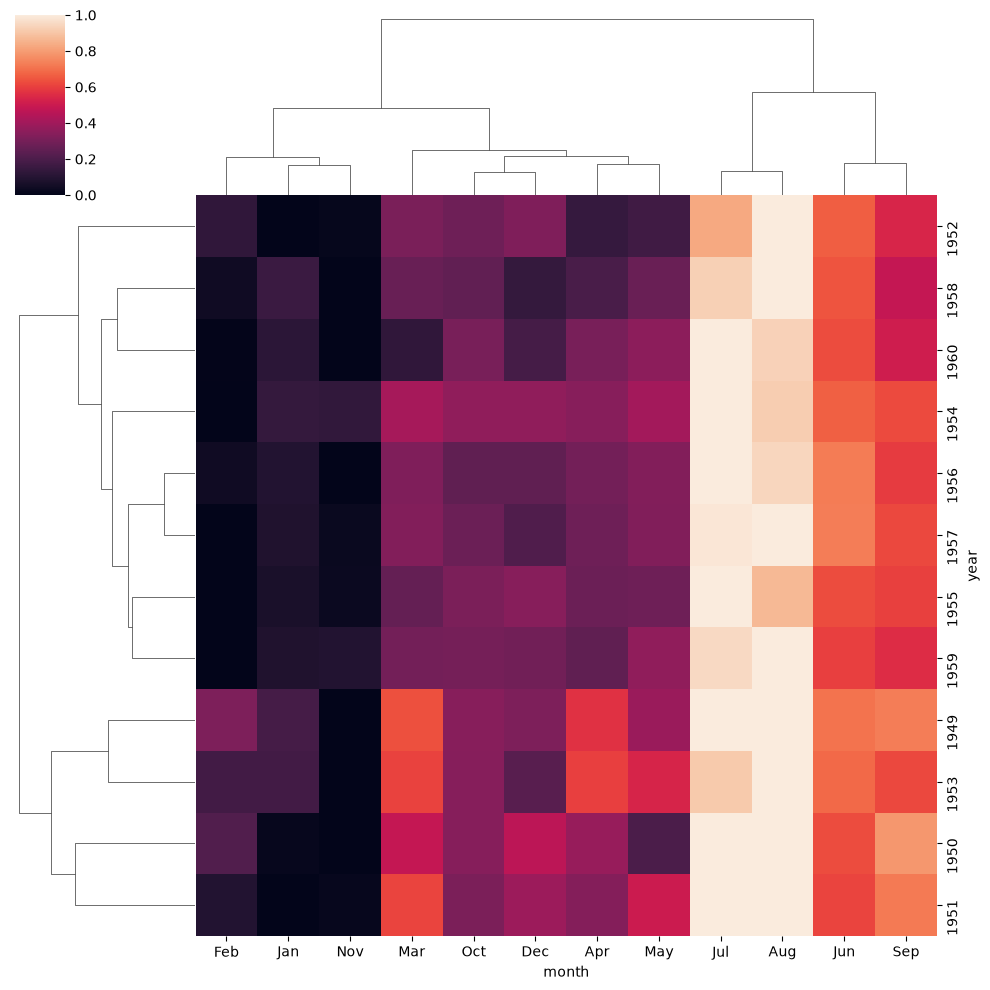

In [76]:
sns.clustermap(fp, standard_scale=0)

In [77]:
titanic = sns.load_dataset("titanic")

titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [78]:
tg = titanic.groupby('class').sum(numeric_only=True)
tg

,survived,pclass,age,sibsp,parch,fare,adult_male,alone
class,,,,,,,,
First,136,216,7111.42,90,77,18177.4125,119,109
Second,87,368,5168.83,74,70,3801.8417,99,104
Third,119,1473,8924.92,302,193,6714.6951,319,324


<Axes: >

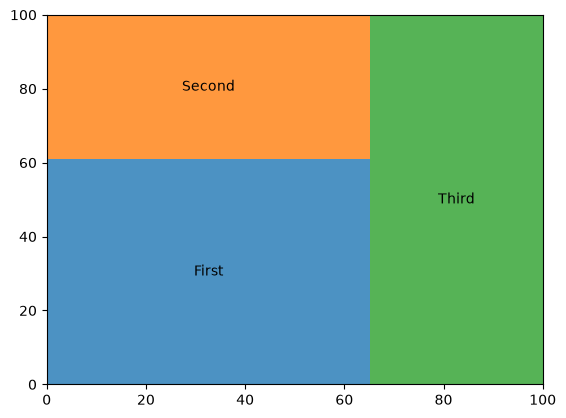

In [79]:
squarify.plot(sizes=tg['survived'], label=tg.index, alpha=.8, color=sns.color_palette('tab10'))

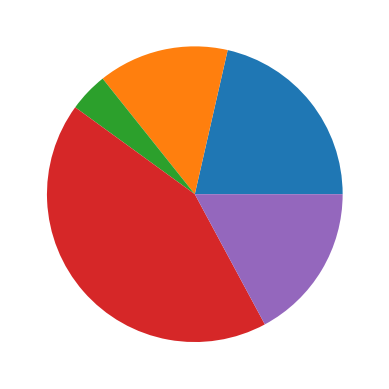

In [87]:
group_sizes = [15, 10, 3, 30, 12]

plt.pie(group_sizes)
plt.show()

circle=plt.Circle((0,0), 0.7, color='white')

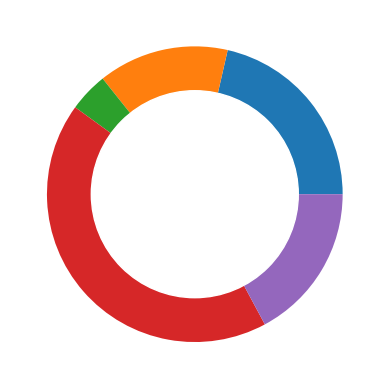

In [88]:
plt.pie(group_sizes)

circle = plt.Circle((0, 0), 0.7, color='white')

fig = plt.gcf()

fig.gca().add_artist(circle)

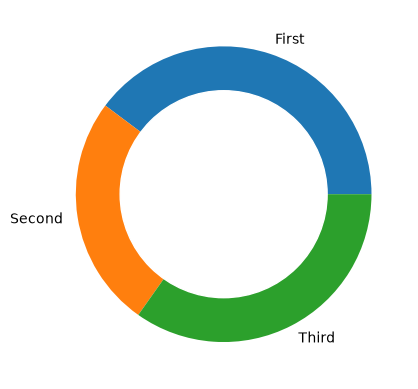

In [81]:
plt.pie(tg['survived'], labels=tg.index)

circle = plt.Circle((0, 0), 0.7, color='white')

fig = plt.gcf()

fig.gca().add_artist(circle)